## 1. Import libraries

Keep all common imports in one place so the notebook is easy to follow.


In [1]:
import os
import joblib
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_curve, auc, f1_score, make_scorer

from statsmodels.stats.outliers_influence import variance_inflation_factor

## 2. Load the datasets

The project uses three files:

- `customers.csv`
- `loans.csv`
- `bureau_data.csv`


In [3]:
customers = pd.read_csv("dataset/customers.csv")
loans = pd.read_csv("dataset/loans.csv")
bureau = pd.read_csv("dataset/bureau_data.csv")

customers.shape, loans.shape, bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [4]:
customers.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,Delhi,110001
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,Tamil Nadu,600001
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,West Bengal,700001


In [5]:
loans.head(3)

,loan_id,cust_id,loan_purpose,loan_type,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,L00001,C00001,Auto,Secured,3004000,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,L00002,C00002,Home,Secured,4161000,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,L00003,C00003,Personal,Unsecured,2401000,2170000,43400.0,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False


In [6]:
bureau.head(3)

,cust_id,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,1,1,42,0,0,3,7
1,C00002,3,1,96,12,60,5,4
2,C00003,2,1,82,24,147,6,58


## 3. Merge the datasets

All three datasets are connected by `cust_id`, so we merge them using this column.


In [7]:
df = customers.merge(loans, on="cust_id", how="inner")
df = df.merge(bureau, on="cust_id", how="inner")

df.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  object 
 1   age                          50000 non-null  int64  
 2   gender                       50000 non-null  object 
 3   marital_status               50000 non-null  object 
 4   employment_status            50000 non-null  object 
 5   income                       50000 non-null  int64  
 6   number_of_dependants         50000 non-null  int64  
 7   residence_type               49938 non-null  object 
 8   years_at_current_address     50000 non-null  int64  
 9   city                         50000 non-null  object 
 10  state                        50000 non-null  object 
 11  zipcode                      50000 non-null  int64  
 12  loan_id                      50000 non-null  object 
 13  loan_purpose    

In [9]:
df["default"] = df["default"].astype(int)
df["default"].value_counts()

default
0    45703
1     4297
Name: count, dtype: int64

`default` is the target column.  
There is class imbalance, so we will handle it later during model training.


## 4. Train-test split

We split the data before EDA and feature engineering decisions.  
This helps avoid data leakage from the test data.


In [10]:
X = df.drop("default", axis="columns")
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

train_df = pd.concat([X_train, y_train], axis="columns")
test_df = pd.concat([X_test, y_test], axis="columns")

train_df.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
12746,C12747,59,M,Married,Self-Employed,11327000,3,Owned,30,Hyderabad,...,2020-10-31,2020-11-11,4,2,152,20,118,4,36,0
32495,C32496,44,F,Single,Salaried,715000,0,Owned,27,Mumbai,...,2022-10-22,2022-10-27,3,1,160,10,62,5,5,0


## 5. Basic data cleaning


In [11]:
train_df.shape


(37500, 33)

In [12]:
train_df.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 47
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [13]:
train_df["residence_type"].unique()

array(['Owned', 'Mortgage', 'Rented', nan], dtype=object)

In [14]:
# Fill missing residence type using only the training data mode.
residence_mode = train_df["residence_type"].mode()[0]

train_df["residence_type"] = train_df["residence_type"].fillna(residence_mode)
test_df["residence_type"] = test_df["residence_type"].fillna(residence_mode)

train_df["residence_type"].unique(), test_df["residence_type"].unique()

(array(['Owned', 'Mortgage', 'Rented'], dtype=object),
 array(['Owned', 'Mortgage', 'Rented'], dtype=object))

In [15]:
train_df.duplicated().sum()

np.int64(0)

In [16]:
train_df.describe()

,age,income,number_of_dependants,years_at_current_address,zipcode,sanction_amount,loan_amount,processing_fee,gst,net_disbursement,...,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
count,37500.000000,3.750000e+04,37500.000000,37500.000000,37500.000000,3.750000e+04,3.750000e+04,3.750000e+04,3.750000e+04,3.750000e+04,...,3.750000e+04,3.750000e+04,37500.000000,37500.000000,37500.00000,37500.000000,37500.000000,37500.000000,37500.000000,37500.000000
mean,39.540587,2.633326e+06,1.944533,15.997787,418866.253333,4.699692e+06,3.996068e+06,8.029068e+04,7.192922e+05,3.196854e+06,...,1.333820e+06,9.862989e+05,2.502907,1.001120,76.11104,4.844853,26.672613,5.008533,43.424880,0.085947
std,9.858344,2.623781e+06,1.535943,8.921041,169035.021773,6.257833e+06,5.371862e+06,1.131281e+05,9.669352e+05,4.297490e+06,...,1.213674e+06,1.043145e+06,1.119070,0.814021,43.76852,5.841396,32.779424,2.029236,29.392857,0.280289
min,18.000000,0.000000e+00,0.000000,1.000000,110001.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,-1.000000e+00,0.000000e+00,1.000000,0.000000,1.00000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,33.000000,8.020000e+05,0.000000,8.000000,302001.000000,1.142000e+06,9.610000e+05,1.922000e+04,1.729800e+05,7.688000e+05,...,4.221975e+05,2.870402e+05,1.000000,0.000000,42.00000,0.000000,0.000000,4.000000,18.000000,0.000000
50%,39.000000,1.885000e+06,2.000000,16.000000,400001.000000,2.644000e+06,2.230000e+06,4.460000e+04,4.014000e+05,1.784000e+06,...,9.974275e+05,6.650145e+05,3.000000,1.000000,71.00000,3.000000,13.000000,5.000000,39.000000,0.000000
75%,46.000000,3.326250e+06,3.000000,24.000000,560001.000000,5.178000e+06,4.619000e+06,9.242000e+04,8.314200e+05,3.695200e+06,...,1.784879e+06,1.234063e+06,4.000000,2.000000,107.00000,8.000000,46.000000,6.000000,67.000000,0.000000
max,70.000000,1.199900e+07,5.000000,31.000000,700001.000000,5.217500e+07,4.781900e+07,5.293544e+06,8.607420e+06,3.825520e+07,...,5.000000e+06,7.846643e+06,4.000000,2.000000,223.00000,24.000000,171.000000,9.000000,99.000000,1.000000


## 6. Define numerical and categorical columns


In [17]:
continuous_columns = [
    "age", "income", "number_of_dependants", "years_at_current_address",
    "sanction_amount", "loan_amount", "processing_fee", "gst", "net_disbursement",
    "loan_tenure_months", "principal_outstanding", "bank_balance_at_application",
    "number_of_open_accounts", "number_of_closed_accounts", "total_loan_months",
    "delinquent_months", "total_dpd", "enquiry_count", "credit_utilization_ratio"
]

categorical_columns = [
    "gender", "marital_status", "employment_status", "residence_type", "city",
    "state", "zipcode", "loan_purpose", "loan_type", "default"
]


## 7. Visualize numerical columns

The first plot checks outliers.  
The second plot checks the distribution of each numerical column.


In [18]:
def plot_columns(data, columns, plot_type="box", columns_per_row=4, figsize_per_plot=(5, 5)):
    total_plots = len(columns)
    total_rows = int(np.ceil(total_plots / columns_per_row))

    fig, axes = plt.subplots(
        total_rows,
        columns_per_row,
        figsize=(figsize_per_plot[0] * columns_per_row, figsize_per_plot[1] * total_rows)
    )

    axes = axes.flatten()

    for index, column in enumerate(columns):
        if plot_type == "box":
            sns.boxplot(x=data[column], ax=axes[index])
        elif plot_type == "hist":
            sns.histplot(data[column], ax=axes[index])

        axes[index].set_title(column)

    for index in range(total_plots, len(axes)):
        axes[index].axis("off")

    plt.tight_layout()
    plt.show()

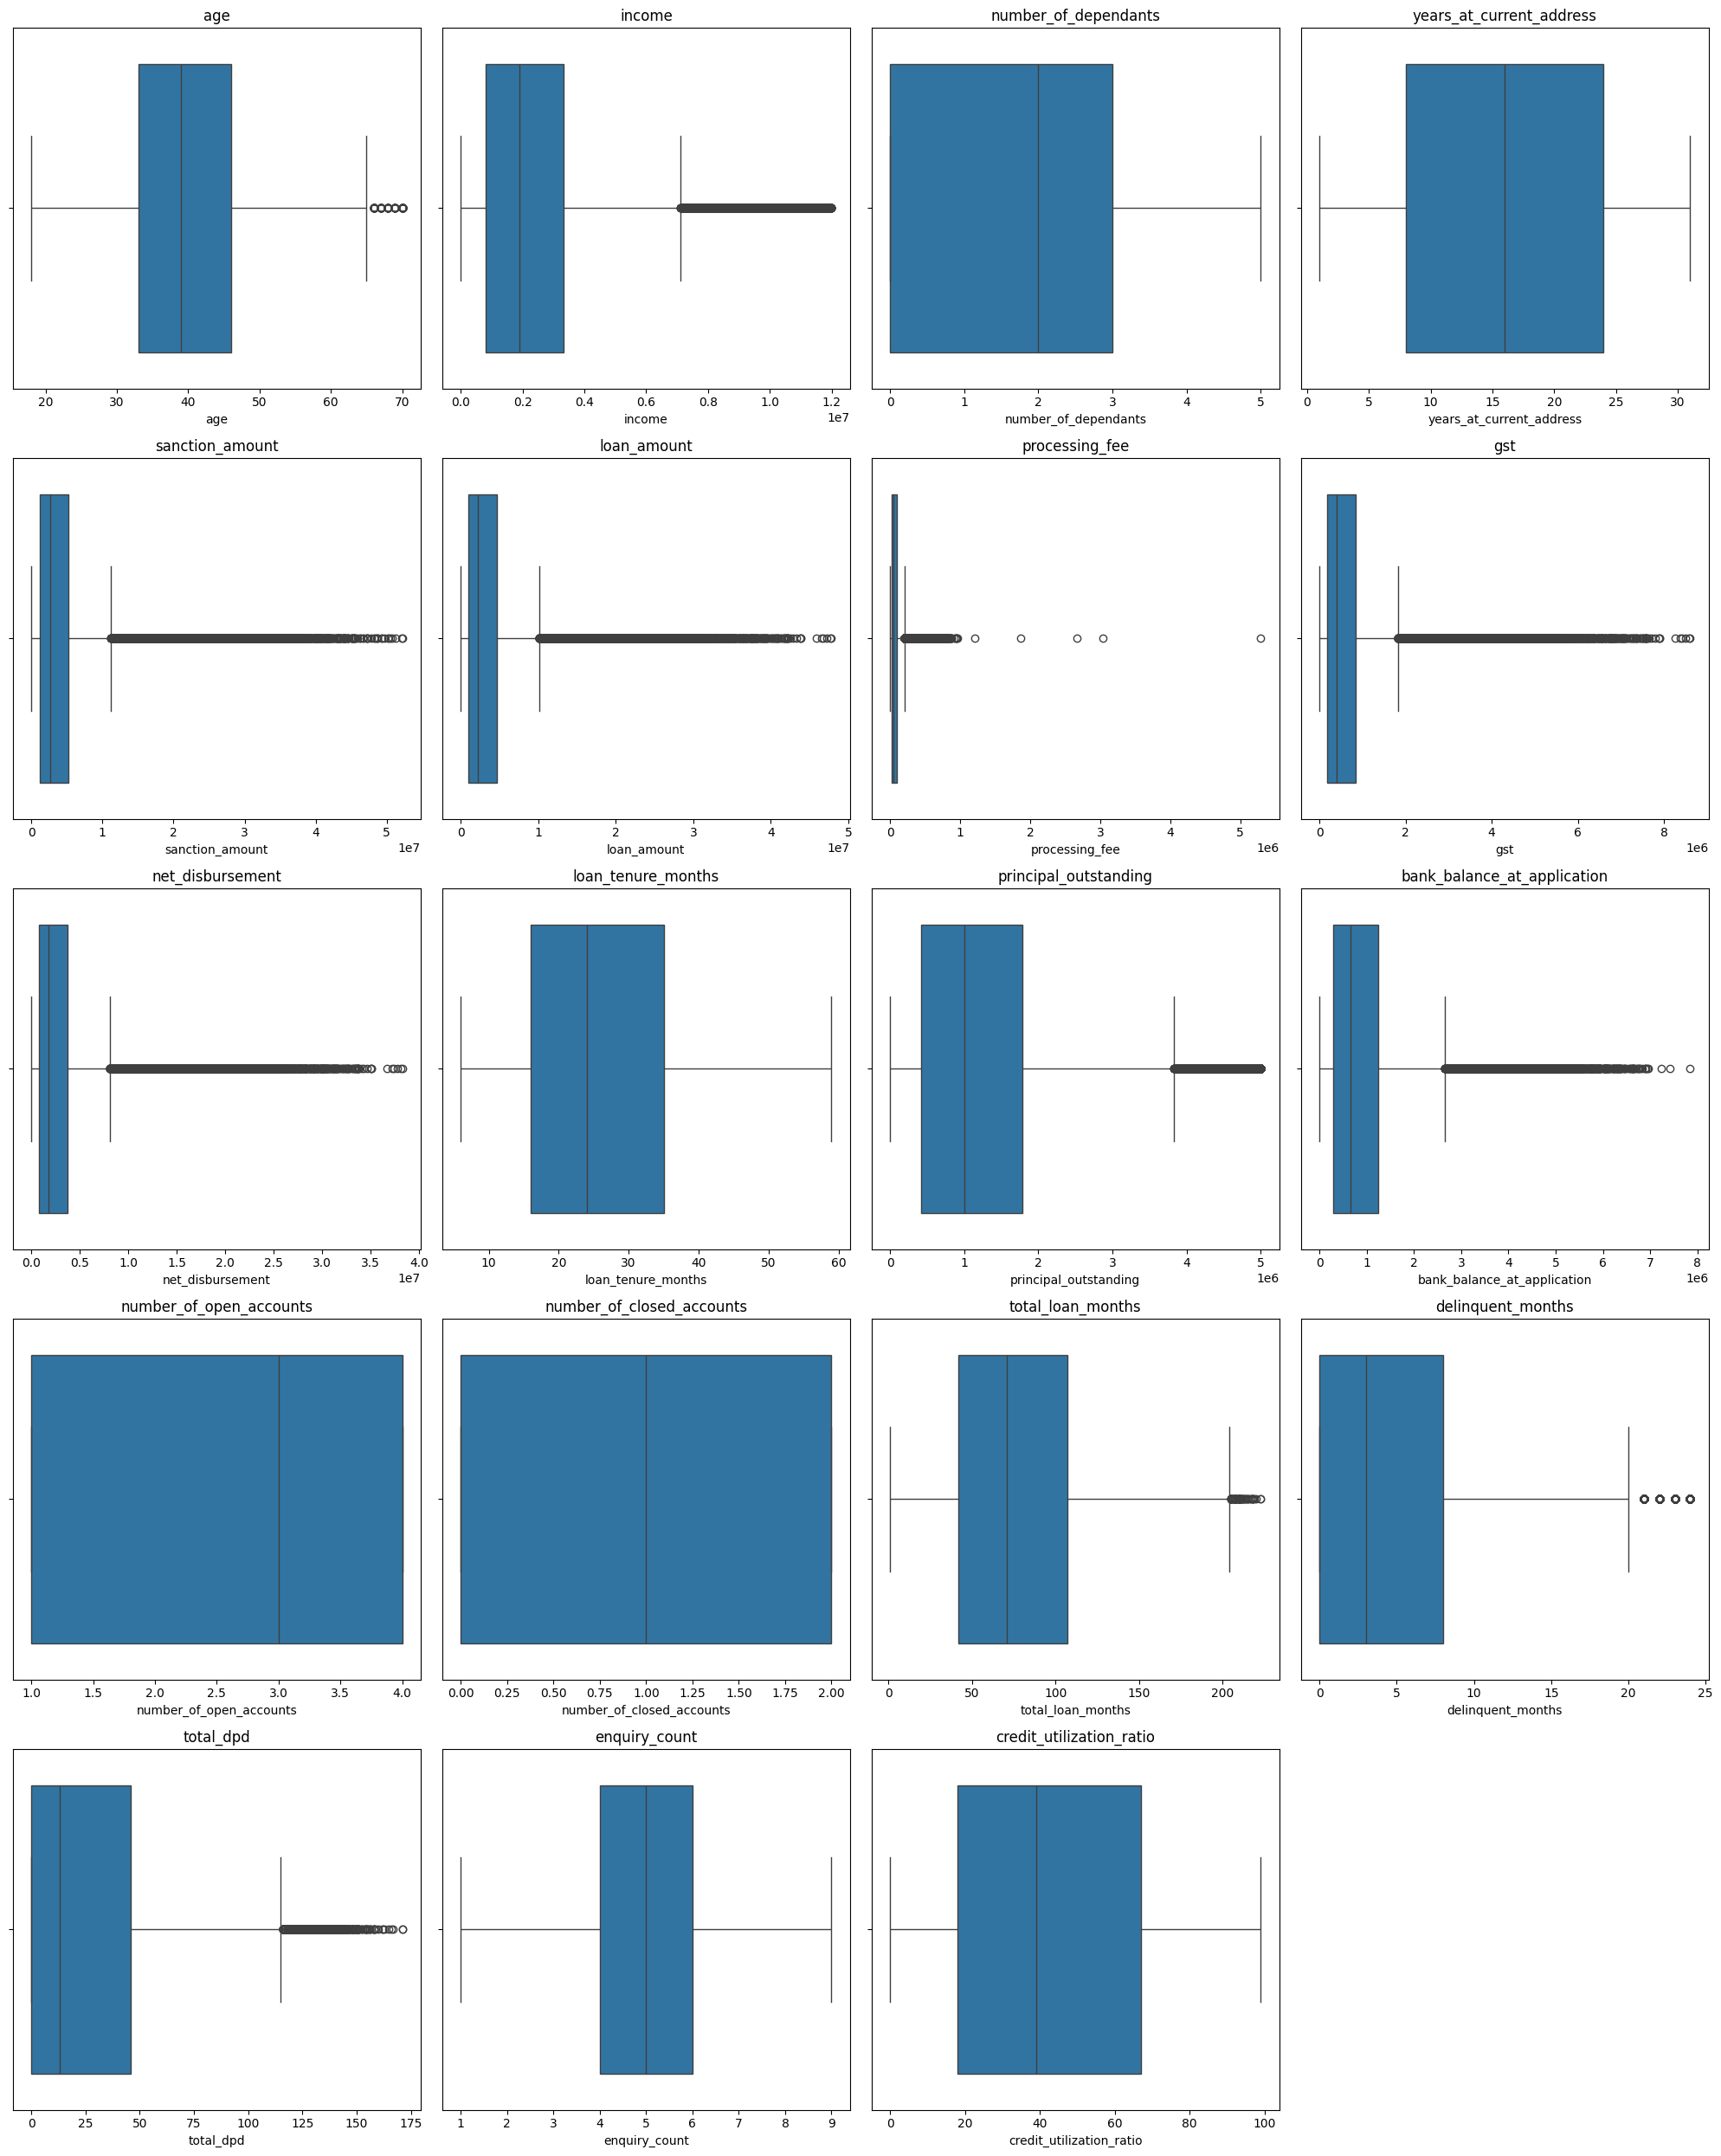

In [19]:
plot_columns(train_df, continuous_columns, plot_type="box")

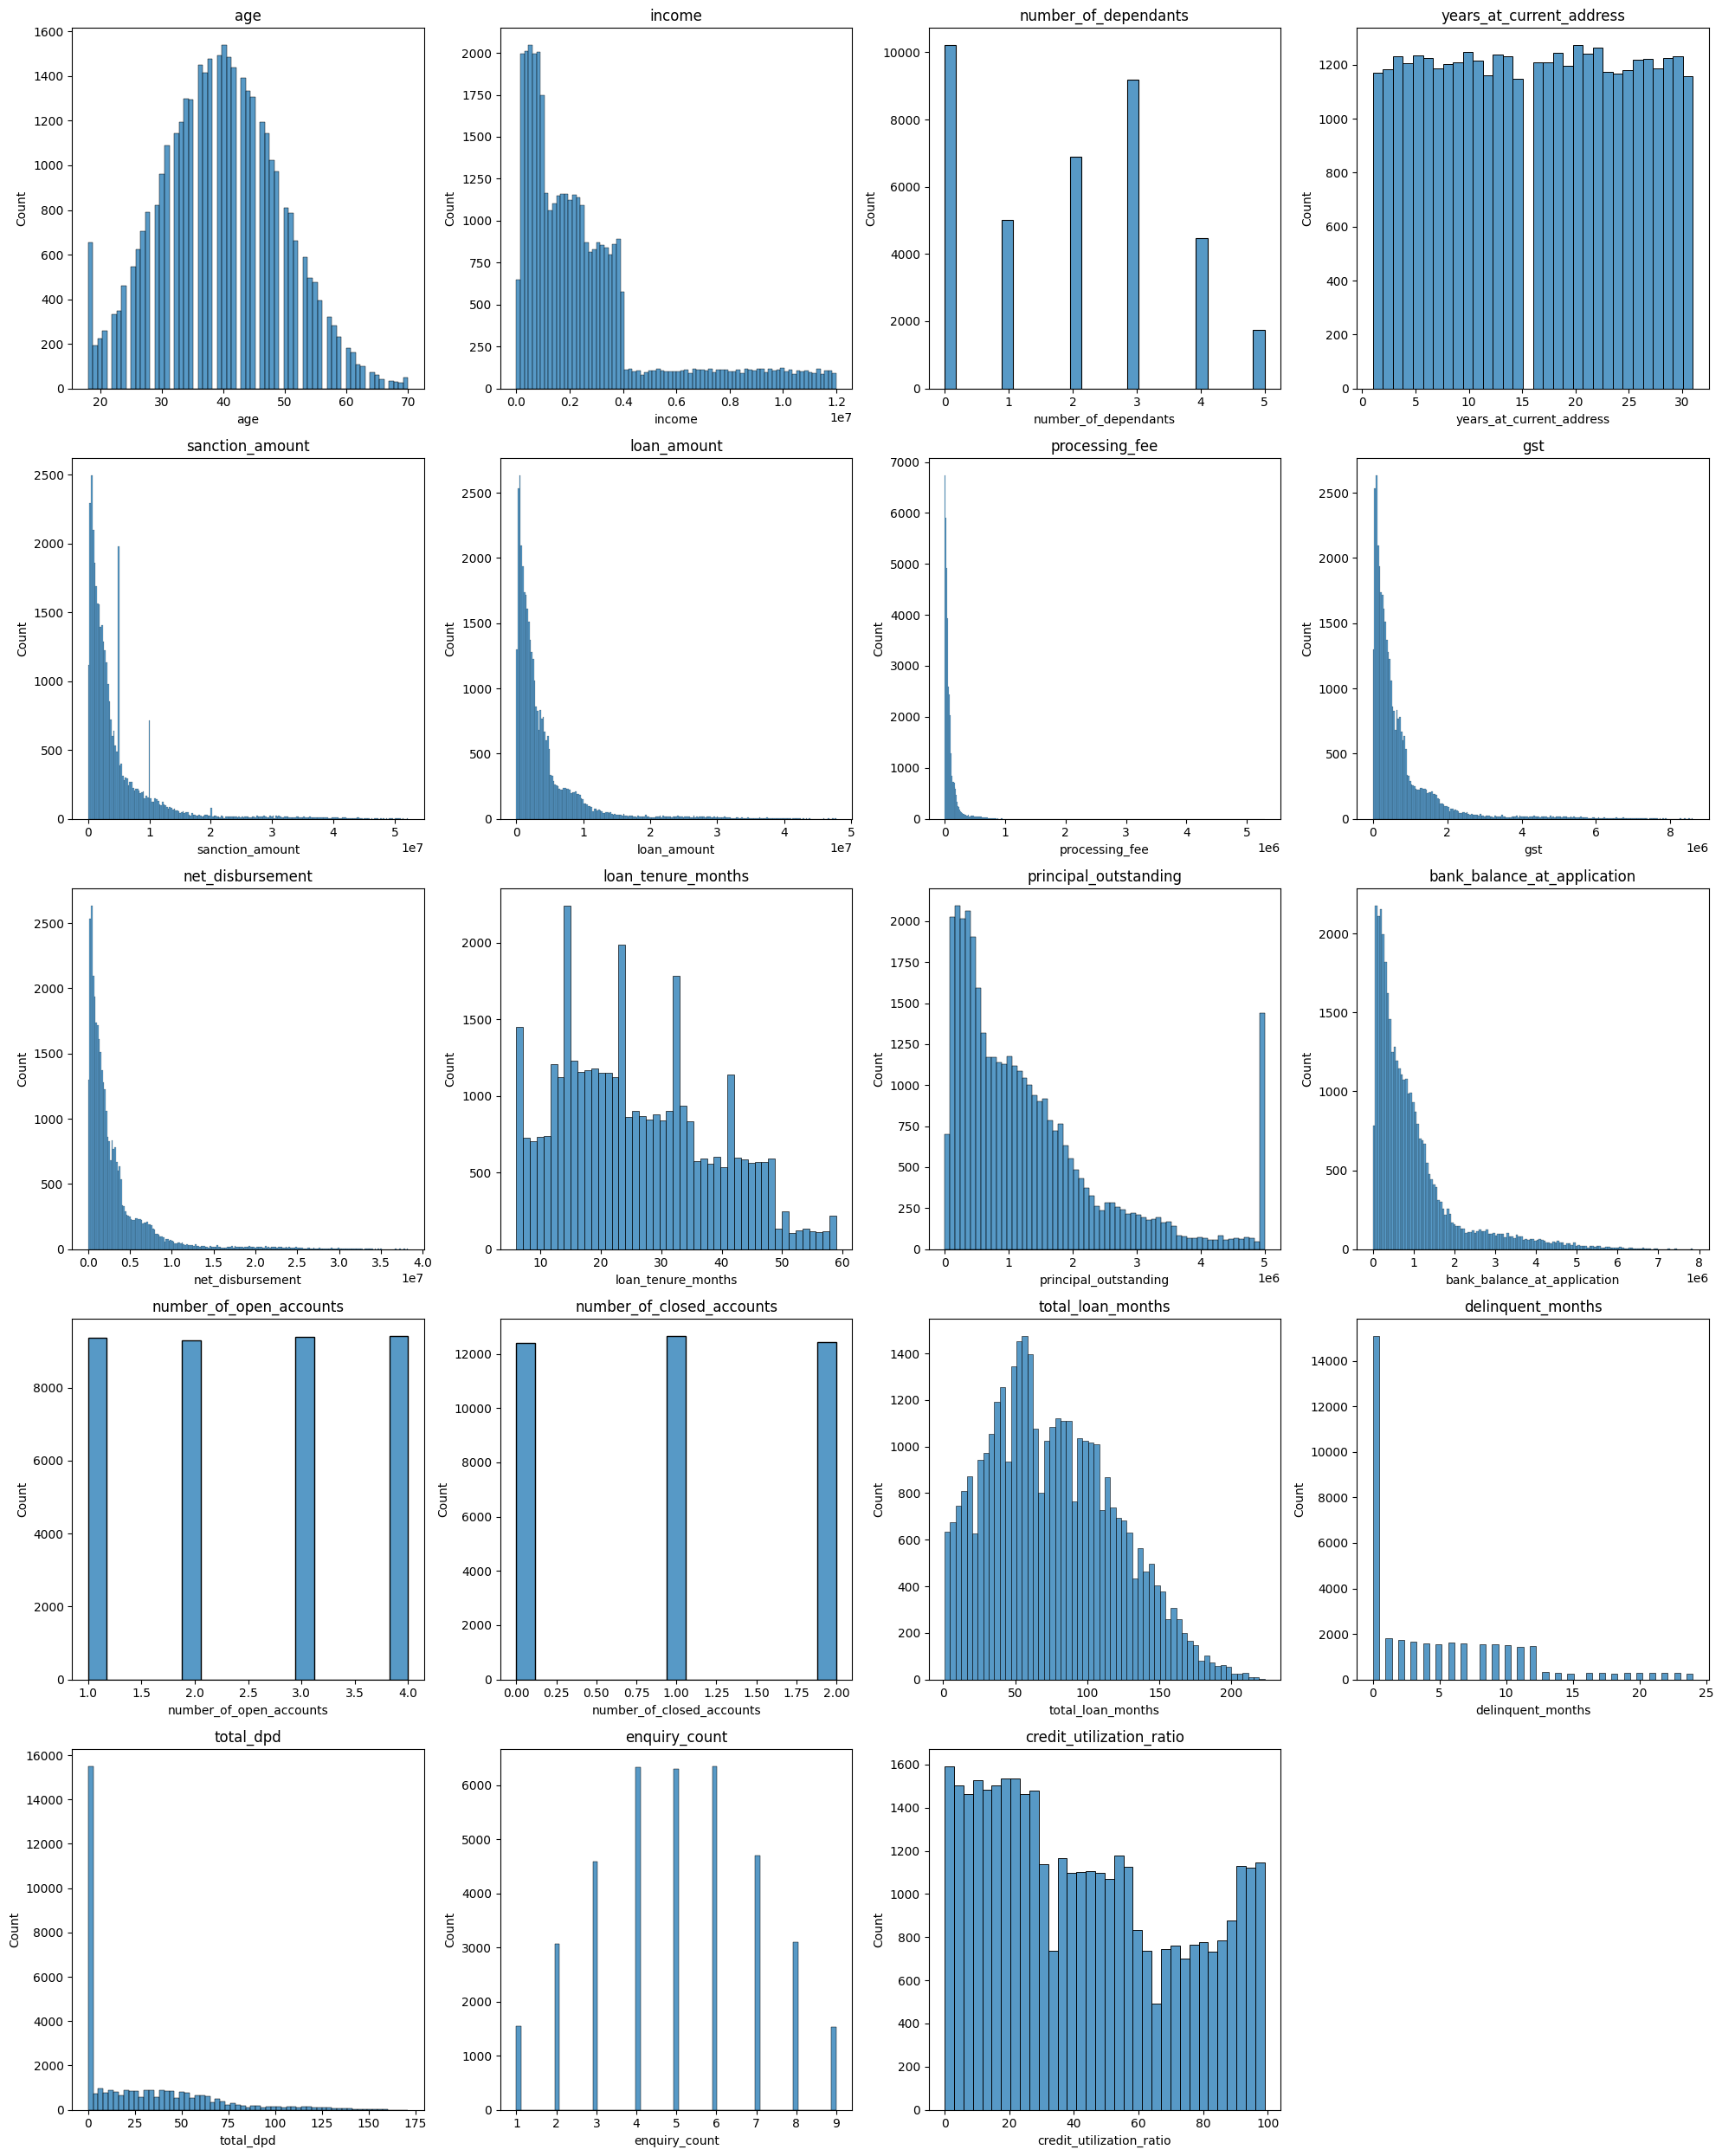

In [20]:
plot_columns(train_df, continuous_columns, plot_type="hist")


## 8. Outlier removal using business rule

Here we remove records where processing fee is more than 3% of the loan amount.


In [21]:
train_df["processing_fee"].describe()

count    3.750000e+04
mean     8.029068e+04
std      1.131281e+05
min      0.000000e+00
25%      1.922000e+04
50%      4.460000e+04
75%      9.242000e+04
max      5.293544e+06
Name: processing_fee, dtype: float64

In [22]:
train_df.loc[
    (train_df["processing_fee"] / train_df["loan_amount"]) > 0.03,
    ["loan_amount", "processing_fee"]
]


,loan_amount,processing_fee
23981,2234000,2.669791e+06
28174,966000,1.214493e+06
47089,1738000,1.858965e+06
29305,2616000,3.036378e+06
9898,3626000,5.293544e+06


In [23]:
train_df_clean = train_df.loc[
    (train_df["processing_fee"] / train_df["loan_amount"]) < 0.03
].copy()

train_df_clean.shape

(37488, 33)

In [24]:
test_df = test_df.loc[
    (test_df["processing_fee"] / test_df["loan_amount"]) < 0.03
].copy()

test_df.shape

(12497, 33)

In [25]:
# Rule 1: GST should not be more than 20% of loan amount.
train_df_clean.loc[
    (train_df_clean["gst"] / train_df_clean["loan_amount"]) > 0.20
].shape


(0, 33)

In [26]:
# Rule 2: Net disbursement should not be higher than loan amount.
train_df_clean.loc[
    train_df_clean["net_disbursement"] > train_df_clean["loan_amount"]
].shape

(0, 33)

## 9. Check categorical columns


In [27]:
for column in categorical_columns:
    print(column, "-->", train_df_clean[column].unique())

gender --> ['M' 'F']
marital_status --> ['Married' 'Single']
employment_status --> ['Self-Employed' 'Salaried']
residence_type --> ['Owned' 'Mortgage' 'Rented']
city --> ['Hyderabad' 'Mumbai' 'Chennai' 'Bangalore' 'Pune' 'Kolkata' 'Ahmedabad'
 'Delhi' 'Lucknow' 'Jaipur']
state --> ['Telangana' 'Maharashtra' 'Tamil Nadu' 'Karnataka' 'West Bengal'
 'Gujarat' 'Delhi' 'Uttar Pradesh' 'Rajasthan']
zipcode --> [500001 400001 600001 560001 411001 700001 380001 110001 226001 302001]
loan_purpose --> ['Home' 'Education' 'Personal' 'Auto' 'Personaal']
loan_type --> ['Secured' 'Unsecured']
default --> [0 1]


In [29]:
# Fix spelling issue in loan purpose.
train_df_clean["loan_purpose"] = train_df_clean["loan_purpose"].replace("Personaal", "Personal")
test_df["loan_purpose"] = test_df["loan_purpose"].replace("Personaal", "Personal")

train_df_clean["loan_purpose"].unique(), test_df["loan_purpose"].unique()

(array(['Home', 'Education', 'Personal', 'Auto'], dtype=object),
 array(['Home', 'Education', 'Auto', 'Personal'], dtype=object))

## 10. Exploratory data analysis


In [30]:
train_df_clean.groupby("default")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
default,,,,,,,,
0,34265.0,39.767693,9.880235,18.0,33.0,40.0,46.0,70.0
1,3223.0,37.124729,9.290168,18.0,31.0,37.0,44.0,70.0


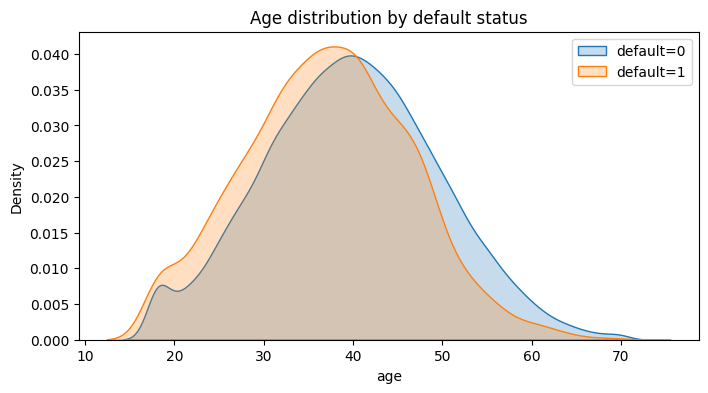

In [31]:
plt.figure(figsize=(8, 4))

sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 0, "age"], fill=True, label="default=0")
sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 1, "age"], fill=True, label="default=1")

plt.title("Age distribution by default status")
plt.legend()
plt.show()


### KDE plots for all numerical columns


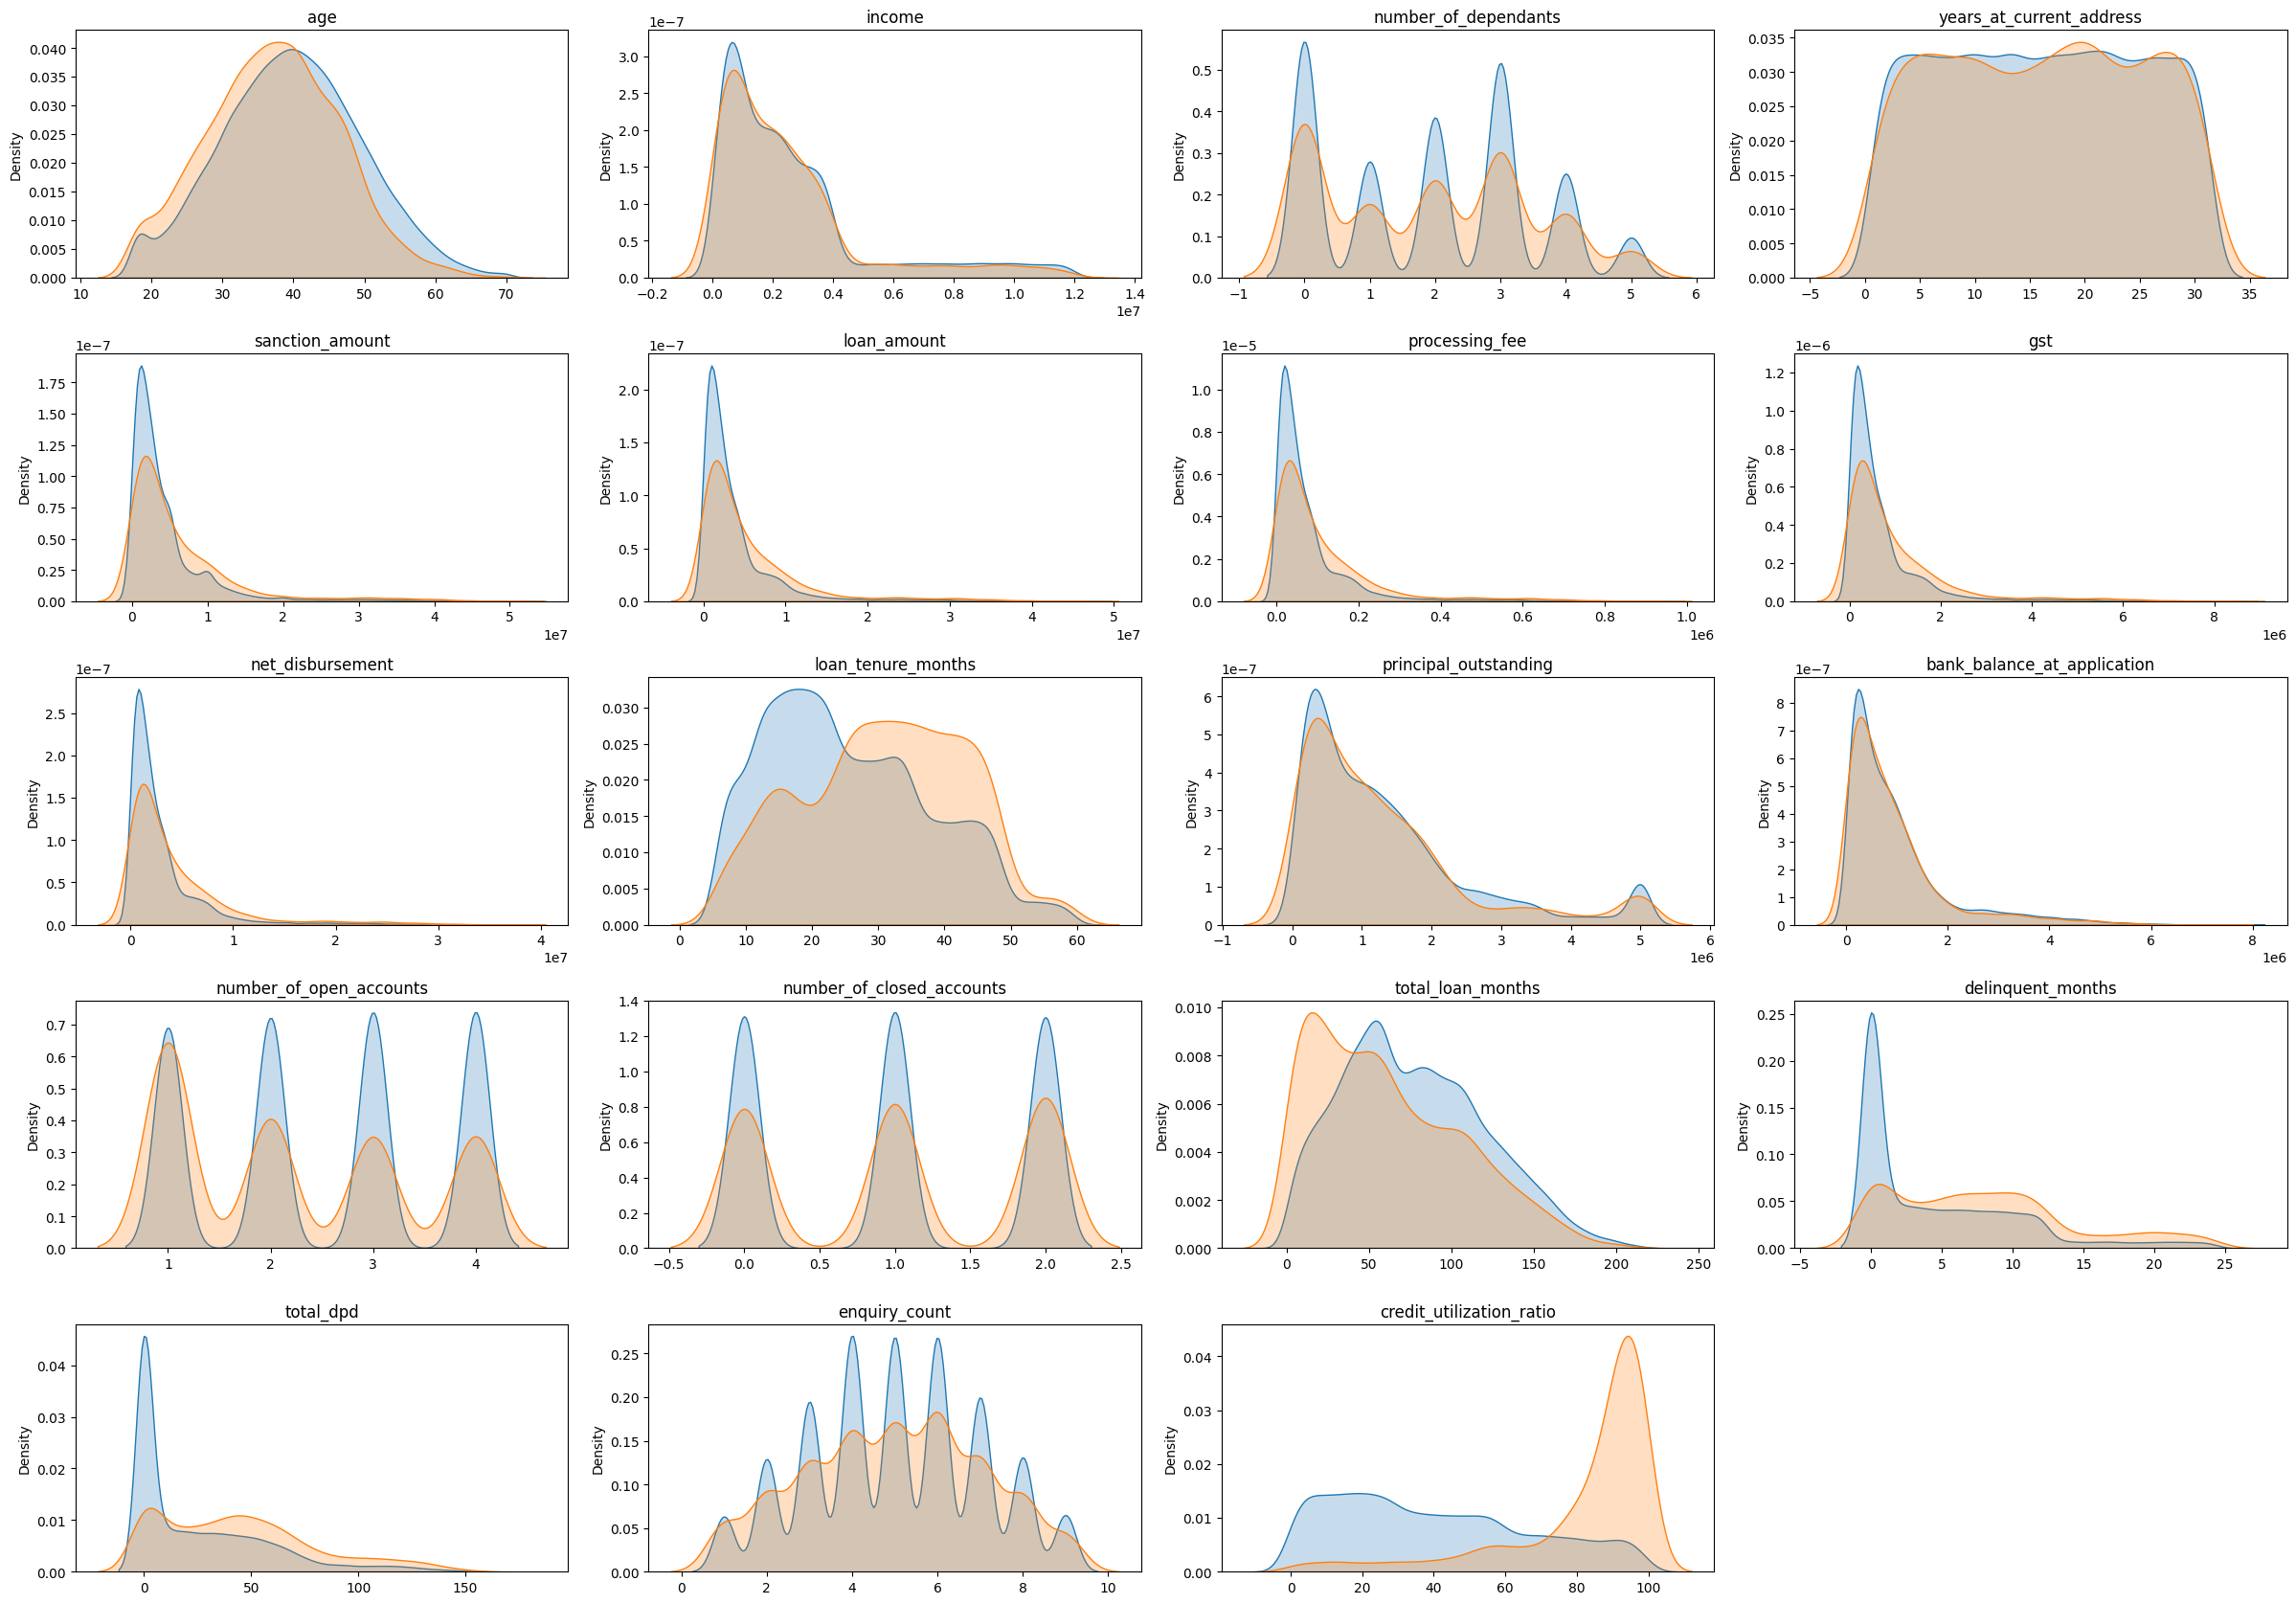

In [32]:
plt.figure(figsize=(24, 20))

for index, column in enumerate(continuous_columns, start=1):
    plt.subplot(6, 4, index)

    sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 0, column], fill=True, label="default=0")
    sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 1, column], fill=True, label="default=1")

    plt.title(column)
    plt.xlabel("")

plt.tight_layout()
plt.show()

Columns such as `loan_tenure_months`, `delinquent_months`, `total_dpd`, and `credit_utilization_ratio` show useful separation between default and non-default customers.


## 11. Feature engineering


### 11.1 Loan-to-income ratio


In [33]:
train_df_clean[["loan_amount", "income"]].head(3)

,loan_amount,income
12746,23442000,11327000
32495,1149000,715000
43675,11296000,3195000


In [34]:
train_df_clean["loan_to_income"] = (train_df_clean["loan_amount"] / train_df_clean["income"]).round(2)
test_df["loan_to_income"] = (test_df["loan_amount"] / test_df["income"]).round(2)

train_df_clean["loan_to_income"].describe()


count    37488.000000
mean         1.556711
std          0.973687
min          0.300000
25%          0.770000
50%          1.160000
75%          2.460000
max          4.570000
Name: loan_to_income, dtype: float64

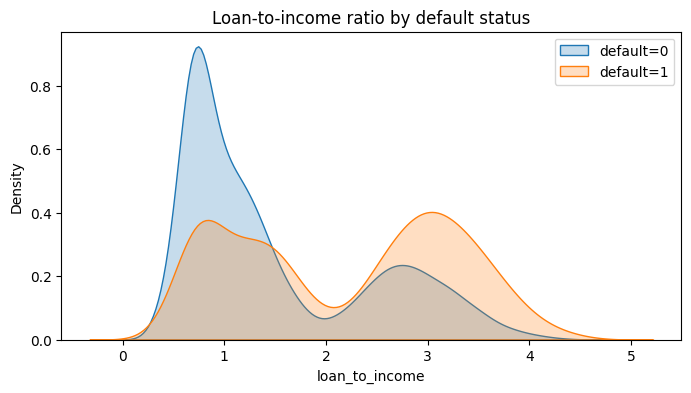

In [35]:
plt.figure(figsize=(8, 4))

sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 0, "loan_to_income"], fill=True, label="default=0")
sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 1, "loan_to_income"], fill=True, label="default=1")

plt.title("Loan-to-income ratio by default status")
plt.legend()
plt.show()

### 11.2 Delinquency ratio


In [36]:
train_df_clean["delinquency_ratio"] = (
    train_df_clean["delinquent_months"] * 100 / train_df_clean["total_loan_months"]
).round(1)

test_df["delinquency_ratio"] = (
    test_df["delinquent_months"] * 100 / test_df["total_loan_months"]
).round(1)


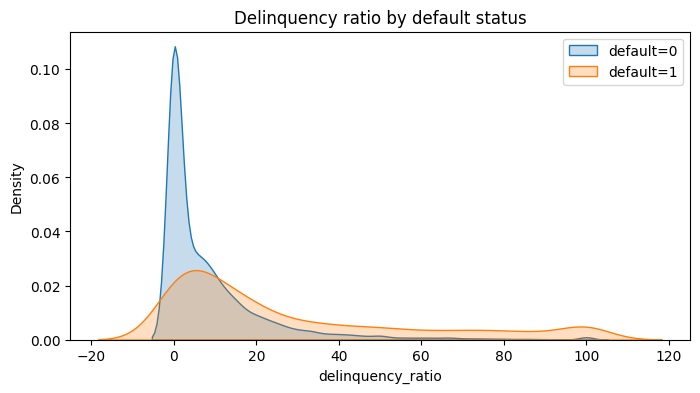

In [37]:
plt.figure(figsize=(8, 4))

sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 0, "delinquency_ratio"], fill=True, label="default=0")
sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 1, "delinquency_ratio"], fill=True, label="default=1")

plt.title("Delinquency ratio by default status")
plt.legend()
plt.show()


### 11.3 Average DPD per delinquency


In [38]:
train_df_clean["avg_dpd_per_delinquency"] = np.where(
    train_df_clean["delinquent_months"] != 0,
    (train_df_clean["total_dpd"] / train_df_clean["delinquent_months"]).round(1),
    0
)

test_df["avg_dpd_per_delinquency"] = np.where(
    test_df["delinquent_months"] != 0,
    (test_df["total_dpd"] / test_df["delinquent_months"]).round(1),
    0
)


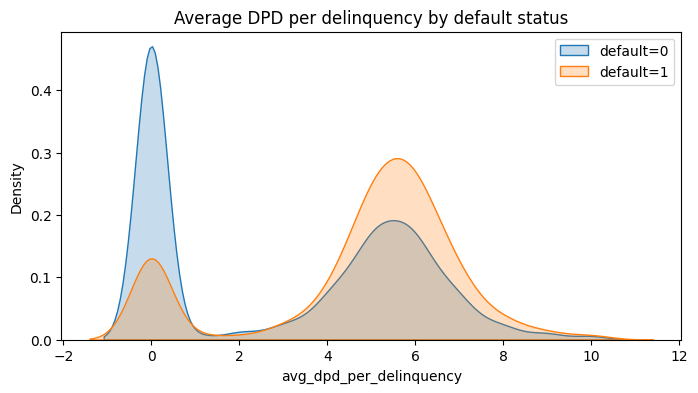

In [39]:
plt.figure(figsize=(8, 4))

sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 0, "avg_dpd_per_delinquency"], fill=True, label="default=0")
sns.kdeplot(train_df_clean.loc[train_df_clean["default"] == 1, "avg_dpd_per_delinquency"], fill=True, label="default=1")

plt.title("Average DPD per delinquency by default status")
plt.legend()
plt.show()

A higher value of average DPD per delinquency is strongly connected with default cases.


## 12. Drop columns not needed for modeling


In [40]:
# Unique IDs do not help the model learn general patterns.
train_df_model = train_df_clean.drop(["cust_id", "loan_id"], axis="columns")
test_df_model = test_df.drop(["cust_id", "loan_id"], axis="columns")


In [41]:
# These columns are removed after deriving useful features from them.
columns_to_remove = [
    "disbursal_date", "installment_start_dt", "loan_amount", "income",
    "total_loan_months", "delinquent_months", "total_dpd"
]

train_df_model = train_df_model.drop(columns_to_remove, axis="columns")
test_df_model = test_df_model.drop(columns_to_remove, axis="columns")

train_df_model.columns


Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency'],
      dtype='object')

## 13. Scaling and VIF check


In [42]:
X_train = train_df_model.drop("default", axis="columns")
y_train = train_df_model["default"]

X_test = test_df_model.drop("default", axis="columns")
y_test = test_df_model["default"]

columns_to_scale = X_train.select_dtypes(include=["int64", "float64"]).columns

scaler = MinMaxScaler()

X_train[columns_to_scale] = scaler.fit_transform(X_train[columns_to_scale])
X_test[columns_to_scale] = scaler.transform(X_test[columns_to_scale])

X_train.describe()


,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000,37488.00000,37488.000000,37488.000000,37488.000000,37488.000000,37488.000000
mean,0.414240,0.388903,0.499918,0.523517,0.088840,0.082513,0.082513,0.082513,0.376631,0.261615,0.123550,0.500925,0.50056,0.501077,0.438653,0.294312,0.103299,0.328391
std,0.189590,0.307182,0.297364,0.286491,0.120117,0.112480,0.112480,0.112480,0.234860,0.244461,0.133275,0.373040,0.40701,0.253666,0.296902,0.228030,0.172985,0.290663
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.288462,0.000000,0.233333,0.325424,0.020555,0.018963,0.018963,0.018963,0.188679,0.077988,0.034205,0.000000,0.00000,0.375000,0.181818,0.110070,0.000000,0.000000
50%,0.403846,0.400000,0.500000,0.491525,0.049364,0.045516,0.045516,0.045516,0.339623,0.193870,0.082515,0.666667,0.50000,0.500000,0.393939,0.201405,0.037000,0.430000
75%,0.538462,0.600000,0.766667,0.762712,0.098027,0.095555,0.095555,0.095555,0.547170,0.352418,0.155192,1.000000,1.00000,0.625000,0.676768,0.505855,0.129000,0.572500
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000


In [43]:
def calculate_vif(data):
    vif_values = []

    for index in range(data.shape[1]):
        vif_values.append(variance_inflation_factor(data.values, index))

    return pd.DataFrame({
        "Column": data.columns,
        "VIF": vif_values
    })


In [44]:
vif_before = calculate_vif(X_train[columns_to_scale])
vif_before


C:\Users\ANANTHU M S\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Column,VIF
0,age,5.700665
1,number_of_dependants,2.730312
2,years_at_current_address,3.422577
3,zipcode,3.797524
4,sanction_amount,101.086559
5,processing_fee,inf
6,gst,inf
7,net_disbursement,inf
8,loan_tenure_months,6.180519
9,principal_outstanding,16.326471


In [45]:
features_to_drop_vif = [
    "sanction_amount", "processing_fee", "gst", "net_disbursement", "principal_outstanding"
]

X_train_selected = X_train.drop(features_to_drop_vif, axis="columns")
X_test_selected = X_test.drop(features_to_drop_vif, axis="columns")

numeric_columns = X_train_selected.select_dtypes(include=["int64", "float64"]).columns
numeric_columns


Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='object')

In [46]:
vif_after = calculate_vif(X_train_selected[numeric_columns])
vif_after


,Column,VIF
0,age,5.429171
1,number_of_dependants,2.726774
2,years_at_current_address,3.403712
3,zipcode,3.777885
4,loan_tenure_months,6.018724
5,bank_balance_at_application,1.804693
6,number_of_open_accounts,4.353487
7,number_of_closed_accounts,2.372449
8,enquiry_count,6.384110
9,credit_utilization_ratio,2.919822


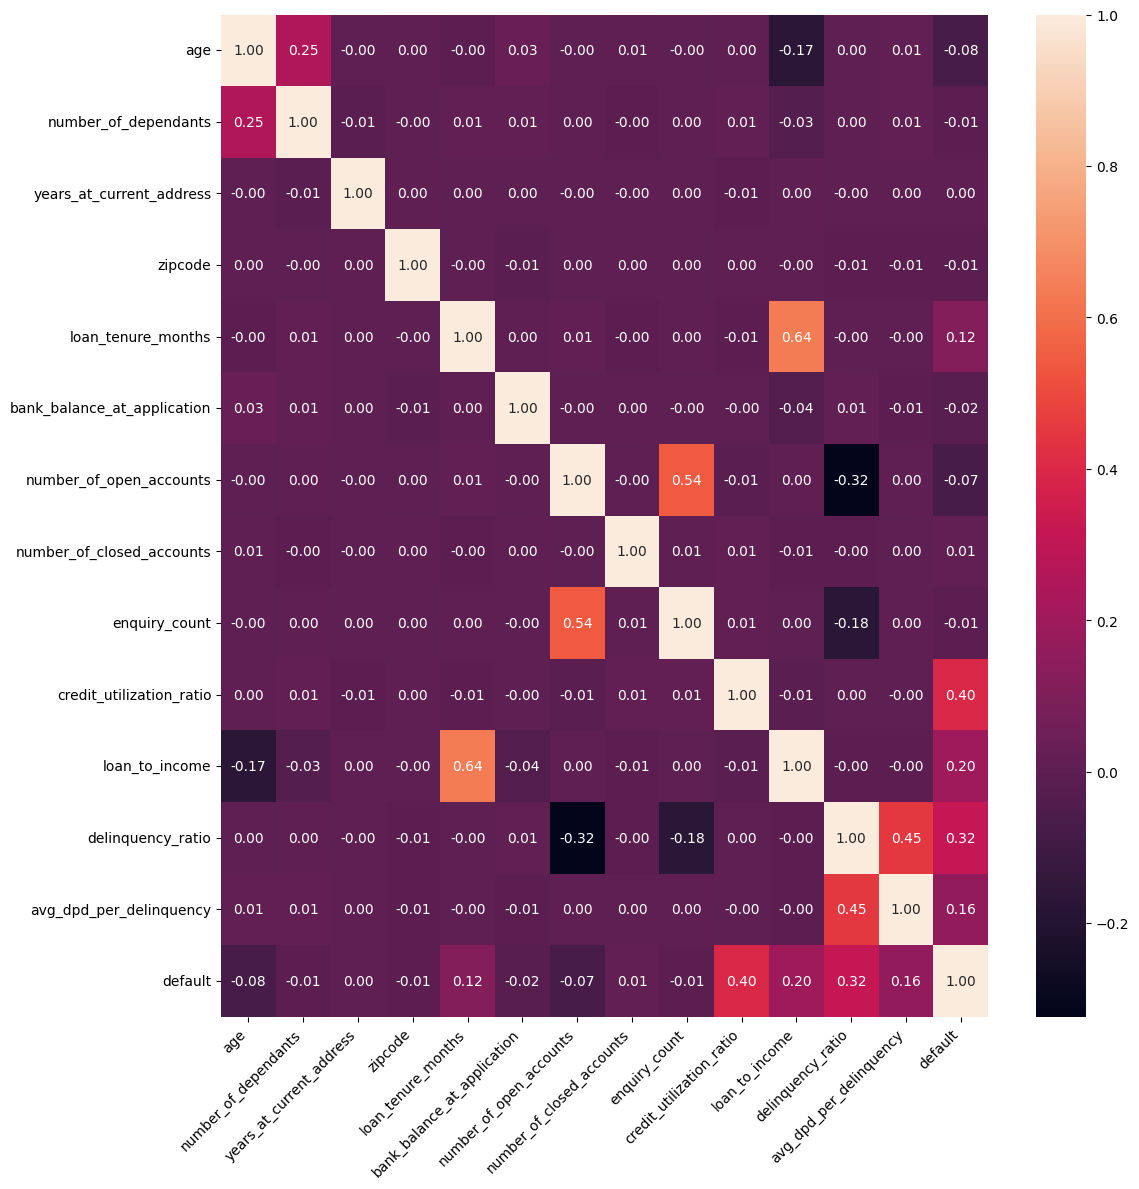

In [47]:
plt.figure(figsize=(12, 12))

correlation_data = pd.concat([X_train_selected[numeric_columns], y_train], axis="columns")
correlation_matrix = correlation_data.corr()

sns.heatmap(correlation_matrix, annot=True, fmt=".2f")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 14. WOE and IV for feature selection

Here, `default = 1` is treated as bad and `default = 0` is treated as good.


In [48]:
def calculate_woe_iv(data, feature, target):
    grouped = data.groupby(feature)[target].agg(["count", "sum"])
    grouped = grouped.rename(columns={"count": "total", "sum": "bad"})

    grouped["good"] = grouped["total"] - grouped["bad"]

    total_good = grouped["good"].sum()
    total_bad = grouped["bad"].sum()

    grouped["good_pct"] = grouped["good"] / total_good
    grouped["bad_pct"] = grouped["bad"] / total_bad

    grouped["woe"] = np.log(grouped["good_pct"] / grouped["bad_pct"])
    grouped["iv"] = (grouped["good_pct"] - grouped["bad_pct"]) * grouped["woe"]

    grouped["woe"] = grouped["woe"].replace([np.inf, -np.inf], 0)
    grouped["iv"] = grouped["iv"].replace([np.inf, -np.inf], 0)

    total_iv = grouped["iv"].sum()

    return grouped, total_iv

In [49]:
woe_table, total_iv = calculate_woe_iv(
    pd.concat([X_train_selected, y_train], axis="columns"),
    "loan_purpose",
    "default"
)

woe_table


,total,bad,good,good_pct,bad_pct,woe,iv
loan_purpose,,,,,,,
Auto,7447,327,7120,0.207792,0.101458,0.716891,0.076230
Education,5620,559,5061,0.147702,0.173441,-0.160642,0.004135
Home,11304,1734,9570,0.279294,0.538008,-0.655609,0.169616
Personal,13117,603,12514,0.365212,0.187093,0.668874,0.119140


In [50]:
total_iv


np.float64(0.3691197842282755)

In [51]:
X_train_selected.info()

<class 'pandas.core.frame.DataFrame'>
Index: 37488 entries, 12746 to 37784
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          37488 non-null  float64
 1   gender                       37488 non-null  object 
 2   marital_status               37488 non-null  object 
 3   employment_status            37488 non-null  object 
 4   number_of_dependants         37488 non-null  float64
 5   residence_type               37488 non-null  object 
 6   years_at_current_address     37488 non-null  float64
 7   city                         37488 non-null  object 
 8   state                        37488 non-null  object 
 9   zipcode                      37488 non-null  float64
 10  loan_purpose                 37488 non-null  object 
 11  loan_type                    37488 non-null  object 
 12  loan_tenure_months           37488 non-null  float64
 13  bank_balance_at_a

In [52]:
iv_values = {}
train_for_iv = pd.concat([X_train_selected, y_train], axis="columns")

for feature in X_train_selected.columns:
    if X_train_selected[feature].dtype == "object":
        _, iv = calculate_woe_iv(train_for_iv, feature, "default")
    else:
        binned_feature = pd.cut(X_train_selected[feature], bins=10, labels=False)
        temp_data = pd.concat([binned_feature, y_train], axis="columns")
        temp_data.columns = [feature, "default"]

        _, iv = calculate_woe_iv(temp_data, feature, "default")

    iv_values[feature] = iv

iv_values

{'age': np.float64(0.0890689462679479),
 'gender': np.float64(0.00047449502170914914),
 'marital_status': np.float64(0.001129766845390139),
 'employment_status': np.float64(0.003953046301722579),
 'number_of_dependants': np.float64(0.0019380899135053517),
 'residence_type': np.float64(0.24674526871814498),
 'years_at_current_address': np.float64(0.002080051360815637),
 'city': np.float64(0.0019059578709781514),
 'state': np.float64(0.0019005589806779276),
 'zipcode': np.float64(0.0016677413243392568),
 'loan_purpose': np.float64(0.3691197842282755),
 'loan_type': np.float64(0.1631932490414922),
 'loan_tenure_months': np.float64(0.21893515090196278),
 'bank_balance_at_application': np.float64(0.006318799327751639),
 'number_of_open_accounts': np.float64(0.08463134083005877),
 'number_of_closed_accounts': np.float64(0.0011964272592421576),
 'enquiry_count': np.float64(0.00786421408534261),
 'credit_utilization_ratio': np.float64(2.352965568168245),
 'loan_to_income': np.float64(0.4764154

In [53]:
iv_df = pd.DataFrame(iv_values.items(), columns=["Feature", "IV"])
iv_df = iv_df.sort_values(by="IV", ascending=False)
iv_df

,Feature,IV
17,credit_utilization_ratio,2.352966
19,delinquency_ratio,0.716576
18,loan_to_income,0.476415
20,avg_dpd_per_delinquency,0.401519
10,loan_purpose,0.369120
5,residence_type,0.246745
12,loan_tenure_months,0.218935
11,loan_type,0.163193
0,age,0.089069
14,number_of_open_accounts,0.084631


In [54]:
# Keep only features with IV greater than 0.02.
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv


['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency']

## 15. Encode categorical features


In [55]:
X_train_reduced = X_train_selected[selected_features_iv]
X_test_reduced = X_test_selected[selected_features_iv]

X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)

# Keep the same columns in train and test.
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

X_train_encoded.head(3)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
12746,0.788462,0.415094,1.000000,0.363636,0.414520,0.132,0.59,True,False,False,True,False,False
32495,0.500000,0.830189,0.666667,0.050505,0.306792,0.062,0.62,True,False,True,False,False,False
43675,0.384615,0.490566,0.000000,0.000000,0.758782,0.222,0.56,False,False,False,True,False,False


In [56]:
X_test_encoded.head(3)


,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
19205,0.346154,0.754717,0.333333,0.989899,0.550351,0.0,0.0,True,False,False,True,False,False
15514,0.480769,0.226415,1.000000,0.323232,0.220141,0.0,0.0,True,False,True,False,False,False
30367,0.230769,0.547170,0.666667,0.828283,0.180328,0.0,0.0,True,False,False,False,False,False


## 16. Model training - Attempt 1

In this attempt, we train models without handling class imbalance.


In [58]:
logistic_model = LogisticRegression(max_iter=10000)
logistic_model.fit(X_train_encoded, y_train)

y_pred = logistic_model.predict(X_test_encoded)
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.85      0.72      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.91      0.85      0.88     12497
weighted avg       0.96      0.96      0.96     12497



In [59]:
def plot_logistic_coefficients(model, feature_names, title="Feature Importance in Logistic Regression"):
    coefficients = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": model.coef_[0]
    })

    coefficients = coefficients.sort_values(by="Coefficient", ascending=True)

    plt.figure(figsize=(8, 4))
    plt.barh(coefficients["Feature"], coefficients["Coefficient"], color="steelblue")
    plt.xlabel("Coefficient Value")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return coefficients

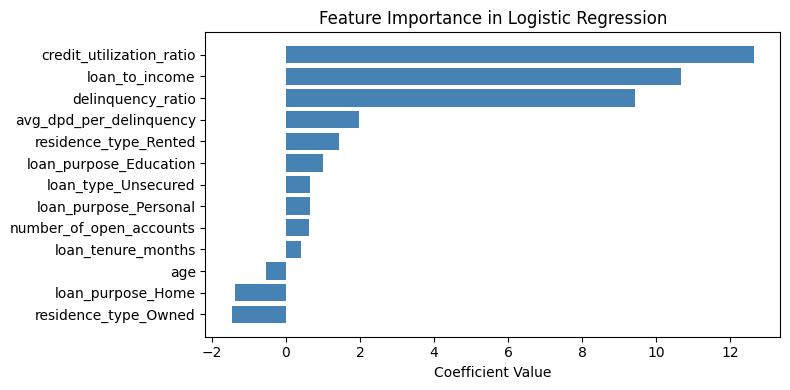

,Feature,Coefficient
7,residence_type_Owned,-1.467980
10,loan_purpose_Home,-1.384710
0,age,-0.530549
1,loan_tenure_months,0.398278
2,number_of_open_accounts,0.635756
11,loan_purpose_Personal,0.638818
12,loan_type_Unsecured,0.638818
9,loan_purpose_Education,0.993052
8,residence_type_Rented,1.444680
6,avg_dpd_per_delinquency,1.970144


In [60]:
logistic_coefficients = plot_logistic_coefficients(logistic_model, X_train_encoded.columns)
logistic_coefficients


In [61]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_encoded, y_train)

y_pred = rf_model.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11423
           1       0.86      0.71      0.78      1074

    accuracy                           0.97     12497
   macro avg       0.91      0.85      0.88     12497
weighted avg       0.96      0.97      0.96     12497



In [62]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(random_state=42)
xgb_model.fit(X_train_encoded, y_train)

y_pred = xgb_model.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98     11423
           1       0.82      0.76      0.79      1074

    accuracy                           0.97     12497
   macro avg       0.90      0.87      0.89     12497
weighted avg       0.96      0.97      0.96     12497



Logistic Regression is easier to interpret, so we continue with it as the main candidate model.


### 16.1 RandomizedSearchCV for Logistic Regression


In [63]:
logistic_params = {
    "C": np.logspace(-4, 4, 20),
    "solver": ["lbfgs", "saga", "liblinear", "newton-cg"]
}

logistic_search = RandomizedSearchCV(
    estimator=LogisticRegression(max_iter=10000),
    param_distributions=logistic_params,
    n_iter=50,
    scoring="f1",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

logistic_search.fit(X_train_encoded, y_train)

print("Best Parameters:", logistic_search.best_params_)
print("Best Score:", logistic_search.best_score_)

best_logistic_attempt_1 = logistic_search.best_estimator_
y_pred = best_logistic_attempt_1.predict(X_test_encoded)

print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameters: {'solver': 'liblinear', 'C': np.float64(1438.44988828766)}
Best Score: 0.7578820896729832
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     11423
           1       0.83      0.74      0.78      1074

    accuracy                           0.96     12497
   macro avg       0.90      0.86      0.88     12497
weighted avg       0.96      0.96      0.96     12497



### 16.2 RandomizedSearchCV for XGBoost


In [64]:
xgb_params = {
    "n_estimators": [100, 150, 200, 250, 300],
    "max_depth": [3, 4, 5, 6, 7, 8, 9, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1.0],
    "scale_pos_weight": [1, 2, 3, 5, 7, 10],
    "reg_alpha": [0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
    "reg_lambda": [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]
}

xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42),
    param_distributions=xgb_params,
    n_iter=100,
    scoring="f1",
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

xgb_search.fit(X_train_encoded, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best Score:", xgb_search.best_score_)

best_xgb_attempt_1 = xgb_search.best_estimator_
y_pred = best_xgb_attempt_1.predict(X_test_encoded)

print(classification_report(y_test, y_pred))


Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best Parameters: {'subsample': 0.7, 'scale_pos_weight': 2, 'reg_lambda': 10.0, 'reg_alpha': 0.01, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.2, 'colsample_bytree': 0.8}
Best Score: 0.7902344570106932
              precision    recall  f1-score   support

           0       0.99      0.98      0.98     11423
           1       0.77      0.84      0.80      1074

    accuracy                           0.96     12497
   macro avg       0.88      0.91      0.89     12497
weighted avg       0.97      0.96      0.97     12497



## 17. Model training - Attempt 2

Here we handle class imbalance using random under-sampling.


In [65]:
from imblearn.under_sampling import RandomUnderSampler

under_sampler = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = under_sampler.fit_resample(X_train_encoded, y_train)

y_train_under.value_counts()

default
0    3223
1    3223
Name: count, dtype: int64

In [66]:
logistic_under = LogisticRegression(max_iter=10000)
logistic_under.fit(X_train_under, y_train_under)

y_pred = logistic_under.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.91      0.95     11423
           1       0.51      0.96      0.67      1074

    accuracy                           0.92     12497
   macro avg       0.75      0.93      0.81     12497
weighted avg       0.95      0.92      0.93     12497



In [67]:
xgb_under = XGBClassifier(**xgb_search.best_params_, random_state=42)
xgb_under.fit(X_train_under, y_train_under)

y_pred = xgb_under.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.92      0.96     11423
           1       0.53      0.98      0.69      1074

    accuracy                           0.92     12497
   macro avg       0.76      0.95      0.82     12497
weighted avg       0.96      0.92      0.93     12497



## 18. Model training - Attempt 3

Here we use SMOTE Tomek and then tune Logistic Regression using Optuna.


In [68]:
from imblearn.combine import SMOTETomek

smote_tomek = SMOTETomek(random_state=42)
X_train_smt, y_train_smt = smote_tomek.fit_resample(X_train_encoded, y_train)

y_train_smt.value_counts()

default
0    34195
1    34195
Name: count, dtype: int64

In [69]:
logistic_smt = LogisticRegression(max_iter=10000)
logistic_smt.fit(X_train_smt, y_train_smt)

y_pred = logistic_smt.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.55      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



In [70]:
import optuna


def logistic_objective(trial):
    params = {
        "C": trial.suggest_float("C", 1e-4, 1e4, log=True),
        "solver": trial.suggest_categorical("solver", ["lbfgs", "liblinear", "saga", "newton-cg"]),
        "tol": trial.suggest_float("tol", 1e-6, 1e-1, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        "max_iter": 10000
    }

    model = LogisticRegression(**params)
    scorer = make_scorer(f1_score, average="macro")

    scores = cross_val_score(
        model,
        X_train_smt,
        y_train_smt,
        cv=3,
        scoring=scorer,
        n_jobs=-1
    )

    return scores.mean()


study_logistic = optuna.create_study(direction="maximize")
study_logistic.optimize(logistic_objective, n_trials=50)


[I 2026-10-13 11:02:05,291] A new study created in memory with name: no-name-3556e251-12f3-4831-9c4f-5464ccafdc62
[I 2026-10-13 11:02:05,435] Trial 0 finished with value: 0.9242523313045506 and parameters: {'C': 0.04038502669004822, 'solver': 'lbfgs', 'tol': 0.003929618446581533, 'class_weight': None}. Best is trial 0 with value: 0.9242523313045506.
[I 2026-10-13 11:02:05,586] Trial 1 finished with value: 0.8822916297420011 and parameters: {'C': 96.89191660141516, 'solver': 'lbfgs', 'tol': 0.03103485582786285, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.9242523313045506.
[I 2026-10-13 11:02:05,882] Trial 2 finished with value: 0.9397555709578206 and parameters: {'C': 0.06588856440097164, 'solver': 'newton-cg', 'tol': 0.00012206619848919141, 'class_weight': None}. Best is trial 2 with value: 0.9397555709578206.
[I 2026-10-13 11:02:06,471] Trial 3 finished with value: 0.9455915325213132 and parameters: {'C': 31.891678265690384, 'solver': 'saga', 'tol': 5.522925391131984e-0

In [71]:
print("Best trial:")
print("F1-score:", study_logistic.best_trial.value)
print("Params:")

for key, value in study_logistic.best_params.items():
    print(f"  {key}: {value}")

best_model_logistic = LogisticRegression(**study_logistic.best_params, max_iter=10000)
best_model_logistic.fit(X_train_smt, y_train_smt)

y_pred = best_model_logistic.predict(X_test_encoded)
print(classification_report(y_test, y_pred))


Best trial:
F1-score: 0.9458675576137013
Params:
  C: 3.9640836976275846
  solver: liblinear
  tol: 7.051943370729448e-05
  class_weight: None
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



## 19. Model training - Attempt 4

Here we tune XGBoost using Optuna.


In [72]:
def xgb_objective(trial):
    params = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "verbosity": 0,
        "booster": "gbtree",
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.4, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "eta": trial.suggest_float("eta", 0.01, 0.3),
        "gamma": trial.suggest_float("gamma", 0, 10),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "max_delta_step": trial.suggest_int("max_delta_step", 0, 10),
        "random_state": 42
    }

    model = XGBClassifier(**params)
    scorer = make_scorer(f1_score, average="macro")

    scores = cross_val_score(
        model,
        X_train_smt,
        y_train_smt,
        cv=3,
        scoring=scorer,
        n_jobs=-1
    )

    return scores.mean()


study_xgb = optuna.create_study(direction="maximize")
study_xgb.optimize(xgb_objective, n_trials=50)


[I 2026-10-13 11:03:26,469] A new study created in memory with name: no-name-edd65b33-09f8-4cf3-a398-38ab7c3c9138
[I 2026-10-13 11:03:27,419] Trial 0 finished with value: 0.9433388399736184 and parameters: {'lambda': 0.015052201100506278, 'alpha': 9.83460954024042, 'subsample': 0.4235715622729395, 'colsample_bytree': 0.7872211571117053, 'max_depth': 3, 'eta': 0.22748166472019962, 'gamma': 9.864602273951238, 'scale_pos_weight': 9.299914778995728, 'min_child_weight': 10, 'max_delta_step': 7}. Best is trial 0 with value: 0.9433388399736184.
[I 2026-10-13 11:03:28,771] Trial 1 finished with value: 0.8984937998535555 and parameters: {'lambda': 0.0029967917369134365, 'alpha': 0.26749095400223344, 'subsample': 0.805317020180068, 'colsample_bytree': 0.7010736827556695, 'max_depth': 6, 'eta': 0.019157350073029225, 'gamma': 1.6458109582032143, 'scale_pos_weight': 8.881271869095336, 'min_child_weight': 10, 'max_delta_step': 0}. Best is trial 0 with value: 0.9433388399736184.
[I 2026-10-13 11:03:3

In [73]:
print("Best trial:")
print("F1-score:", study_xgb.best_trial.value)
print("Params:")

for key, value in study_xgb.best_params.items():
    print(f"  {key}: {value}")

best_model_xgb = XGBClassifier(**study_xgb.best_params, random_state=42)
best_model_xgb.fit(X_train_smt, y_train_smt)

y_pred = best_model_xgb.predict(X_test_encoded)
print(classification_report(y_test, y_pred))


Best trial:
F1-score: 0.9766587410987208
Params:
  lambda: 0.002213492857531621
  alpha: 0.009116602380913996
  subsample: 0.8450599622612677
  colsample_bytree: 0.8163840599905628
  max_depth: 9
  eta: 0.2669993695654413
  gamma: 0.4653285133280791
  scale_pos_weight: 1.011275261818494
  min_child_weight: 7
  max_delta_step: 1
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     11423
           1       0.75      0.83      0.79      1074

    accuracy                           0.96     12497
   macro avg       0.87      0.90      0.89     12497
weighted avg       0.96      0.96      0.96     12497



## 20. ROC-AUC evaluation

We use the final Logistic Regression model for evaluation and deployment.


In [74]:
y_pred = best_model_logistic.predict(X_test_encoded)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11423
           1       0.56      0.94      0.70      1074

    accuracy                           0.93     12497
   macro avg       0.77      0.94      0.83     12497
weighted avg       0.96      0.93      0.94     12497



In [75]:
default_probabilities = best_model_logistic.predict_proba(X_test_encoded)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, default_probabilities)
roc_auc = auc(fpr, tpr)

roc_auc

0.9836795670664122

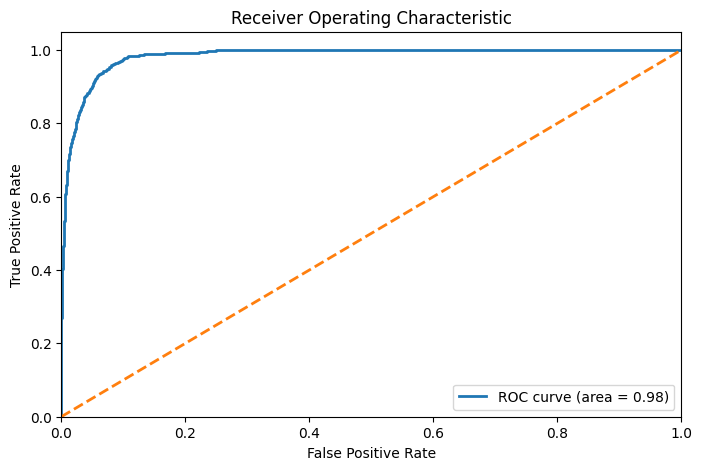

In [76]:
plt.figure(figsize=(8, 5))

plt.plot(fpr, tpr, lw=2, label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], lw=2, linestyle="--")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic")
plt.legend(loc="lower right")
plt.show()

## 21. Rank ordering, KS statistic, and Gini coefficient


In [77]:
evaluation_df = pd.DataFrame({
    "Default Truth": y_test,
    "Default Probability": default_probabilities
})

evaluation_df.head(3)

,Default Truth,Default Probability
19205,0,0.535574
15514,0,0.000013
30367,0,0.006033


In [78]:
evaluation_df["Decile"] = pd.qcut(
    evaluation_df["Default Probability"],
    10,
    labels=False,
    duplicates="drop"
)

evaluation_df.head(3)

,Default Truth,Default Probability,Decile
19205,0,0.535574,8
15514,0,0.000013,2
30367,0,0.006033,6


In [79]:
evaluation_df.loc[evaluation_df["Decile"] == 8, "Default Probability"].describe()

count    1250.000000
mean        0.486841
std         0.180780
min         0.216854
25%         0.319881
50%         0.468605
75%         0.641936
max         0.817425
Name: Default Probability, dtype: float64

In [80]:
decile_df = evaluation_df.groupby("Decile").apply(
    lambda group: pd.Series({
        "Minimum Probability": group["Default Probability"].min(),
        "Maximum Probability": group["Default Probability"].max(),
        "Events": group["Default Truth"].sum(),
        "Non-events": group["Default Truth"].count() - group["Default Truth"].sum()
    })
).reset_index()

decile_df

C:\Users\ANANTHU M S\AppData\Local\Temp\ipykernel_10980\2367629766.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  decile_df = evaluation_df.groupby("Decile").apply(


,Decile,Minimum Probability,Maximum Probability,Events,Non-events
0,0,1.659811e-09,9.147070e-07,0.0,1250.0
1,1,9.181888e-07,6.896849e-06,0.0,1250.0
2,2,6.897863e-06,3.398018e-05,0.0,1249.0
3,3,3.401026e-05,1.706507e-04,0.0,1250.0
4,4,1.709845e-04,8.407606e-04,0.0,1250.0
5,5,8.408159e-04,4.661036e-03,0.0,1249.0
6,6,4.672248e-03,3.027429e-02,5.0,1245.0
7,7,3.039007e-02,2.165670e-01,9.0,1240.0
8,8,2.168538e-01,8.174249e-01,161.0,1089.0
9,9,8.176432e-01,1.000000e+00,899.0,351.0


In [81]:
decile_df["Event Rate"] = decile_df["Events"] * 100 / (decile_df["Events"] + decile_df["Non-events"])
decile_df["Non-event Rate"] = decile_df["Non-events"] * 100 / (decile_df["Events"] + decile_df["Non-events"])

decile_df

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,0,1.659811e-09,9.147070e-07,0.0,1250.0,0.000000,100.000000
1,1,9.181888e-07,6.896849e-06,0.0,1250.0,0.000000,100.000000
2,2,6.897863e-06,3.398018e-05,0.0,1249.0,0.000000,100.000000
3,3,3.401026e-05,1.706507e-04,0.0,1250.0,0.000000,100.000000
4,4,1.709845e-04,8.407606e-04,0.0,1250.0,0.000000,100.000000
5,5,8.408159e-04,4.661036e-03,0.0,1249.0,0.000000,100.000000
6,6,4.672248e-03,3.027429e-02,5.0,1245.0,0.400000,99.600000
7,7,3.039007e-02,2.165670e-01,9.0,1240.0,0.720576,99.279424
8,8,2.168538e-01,8.174249e-01,161.0,1089.0,12.880000,87.120000
9,9,8.176432e-01,1.000000e+00,899.0,351.0,71.920000,28.080000


In [82]:
# Higher deciles have higher predicted default probabilities.
decile_df = decile_df.sort_values(by="Decile", ascending=False).reset_index(drop=True)
decile_df

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate
0,9,8.176432e-01,1.000000e+00,899.0,351.0,71.920000,28.080000
1,8,2.168538e-01,8.174249e-01,161.0,1089.0,12.880000,87.120000
2,7,3.039007e-02,2.165670e-01,9.0,1240.0,0.720576,99.279424
3,6,4.672248e-03,3.027429e-02,5.0,1245.0,0.400000,99.600000
4,5,8.408159e-04,4.661036e-03,0.0,1249.0,0.000000,100.000000
5,4,1.709845e-04,8.407606e-04,0.0,1250.0,0.000000,100.000000
6,3,3.401026e-05,1.706507e-04,0.0,1250.0,0.000000,100.000000
7,2,6.897863e-06,3.398018e-05,0.0,1249.0,0.000000,100.000000
8,1,9.181888e-07,6.896849e-06,0.0,1250.0,0.000000,100.000000
9,0,1.659811e-09,9.147070e-07,0.0,1250.0,0.000000,100.000000


In [83]:
decile_df["Cum Events"] = decile_df["Events"].cumsum()
decile_df["Cum Non-events"] = decile_df["Non-events"].cumsum()

decile_df["Cum Event Rate"] = decile_df["Cum Events"] * 100 / decile_df["Events"].sum()
decile_df["Cum Non-event Rate"] = decile_df["Cum Non-events"] * 100 / decile_df["Non-events"].sum()

decile_df["KS"] = abs(decile_df["Cum Event Rate"] - decile_df["Cum Non-event Rate"])

decile_df

,Decile,Minimum Probability,Maximum Probability,Events,Non-events,Event Rate,Non-event Rate,Cum Events,Cum Non-events,Cum Event Rate,Cum Non-event Rate,KS
0,9,8.176432e-01,1.000000e+00,899.0,351.0,71.920000,28.080000,899.0,351.0,83.705773,3.072748,80.633025
1,8,2.168538e-01,8.174249e-01,161.0,1089.0,12.880000,87.120000,1060.0,1440.0,98.696462,12.606145,86.090316
2,7,3.039007e-02,2.165670e-01,9.0,1240.0,0.720576,99.279424,1069.0,2680.0,99.534451,23.461437,76.073013
3,6,4.672248e-03,3.027429e-02,5.0,1245.0,0.400000,99.600000,1074.0,3925.0,100.000000,34.360501,65.639499
4,5,8.408159e-04,4.661036e-03,0.0,1249.0,0.000000,100.000000,1074.0,5174.0,100.000000,45.294581,54.705419
5,4,1.709845e-04,8.407606e-04,0.0,1250.0,0.000000,100.000000,1074.0,6424.0,100.000000,56.237416,43.762584
6,3,3.401026e-05,1.706507e-04,0.0,1250.0,0.000000,100.000000,1074.0,7674.0,100.000000,67.180250,32.819750
7,2,6.897863e-06,3.398018e-05,0.0,1249.0,0.000000,100.000000,1074.0,8923.0,100.000000,78.114331,21.885669
8,1,9.181888e-07,6.896849e-06,0.0,1250.0,0.000000,100.000000,1074.0,10173.0,100.000000,89.057165,10.942835
9,0,1.659811e-09,9.147070e-07,0.0,1250.0,0.000000,100.000000,1074.0,11423.0,100.000000,100.000000,0.000000


In [84]:
gini_coefficient = 2 * roc_auc - 1

print("AUC:", roc_auc)
print("Gini Coefficient:", gini_coefficient)

AUC: 0.9836795670664122
Gini Coefficient: 0.9673591341328245


Rank ordering is good when the higher-risk deciles show higher event rates than the lower-risk deciles.


## 22. Final model and feature importance


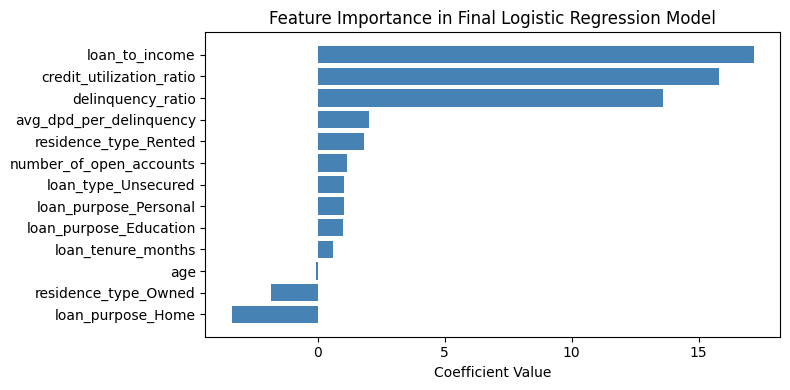

,Feature,Coefficient
10,loan_purpose_Home,-3.394599
7,residence_type_Owned,-1.833174
0,age,-0.056876
1,loan_tenure_months,0.607279
9,loan_purpose_Education,1.000836
11,loan_purpose_Personal,1.036941
12,loan_type_Unsecured,1.036941
2,number_of_open_accounts,1.161092
8,residence_type_Rented,1.827752
6,avg_dpd_per_delinquency,2.029985


In [85]:
final_model = best_model_logistic

final_coefficients = plot_logistic_coefficients(
    final_model,
    X_train_encoded.columns,
    title="Feature Importance in Final Logistic Regression Model"
)

final_coefficients

## 23. Save the final model

This creates the `model_data.joblib` file used by the Streamlit app.


In [86]:
X_test_encoded.head(2)

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
19205,0.346154,0.754717,0.333333,0.989899,0.550351,0.0,0.0,True,False,False,True,False,False
15514,0.480769,0.226415,1.000000,0.323232,0.220141,0.0,0.0,True,False,True,False,False,False


In [87]:
X_test_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='object')

In [88]:
columns_to_scale

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='object')

In [89]:
X_train_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='object')

In [90]:
os.makedirs("artifacts", exist_ok=True)

model_data = {
    "model": final_model,
    "features": X_train_encoded.columns,
    "scaler": scaler,
    "cols_to_scale": columns_to_scale
}

joblib.dump(model_data, "artifacts/model_data.joblib")

['artifacts/model_data.joblib']

In [91]:
final_model.coef_, final_model.intercept_

(array([[-0.05687635,  0.60727927,  1.16109189, 15.79743506, 17.17753083,
         13.59920419,  2.02998541, -1.83317428,  1.82775245,  1.00083633,
         -3.39459883,  1.03694079,  1.03694079]]),
 array([-20.5468977]))